In [21]:
%load_ext autoreload
%autoreload 2
import json
import os
import sys

import torch

sys.path.append('..')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from predict import predict

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f" Device: {device}")

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_ds = datasets.ImageFolder('../data/processed/val', transform=eval_tf)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=0)
print(f" val_ds: {len(val_ds)} images")
print(f" classes: {val_ds.classes}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
 Device: cuda
 val_ds: 423 images
 classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']


In [16]:
ckpt = torch.load('../checkpoints/resnet_ft.pt', weights_only=False)
ckpt['architecture'] = 'resnet18'
ckpt['class_names'] = val_ds.classes
ckpt['class_to_idx'] = val_ds.class_to_idx
ckpt['threshold'] = 0.70
ckpt['seed'] = 42

torch.save(ckpt, '../checkpoints/resnet_ft.pt')
print(f" Metadata saved: {list(ckpt.keys())}")

 Metadata saved: ['model_state_dict', 'epoch', 'val_macro_f1', 'lr_layer4', 'lr_head', 'trainable', 'img_size', 'architecture', 'class_names', 'class_to_idx', 'threshold', 'seed']


In [24]:
img_ambulance = os.path.join(
    '../data/processed/val/ambulance',
    os.listdir('../data/processed/val/ambulance')[0]
)
img_kamyun = os.path.join(
    '../data/processed/val/kamyun',
    os.listdir('../data/processed/val/kamyun')[0]
)
img_neysan = os.path.join(
    '../data/raw/dataset/neysan_val',
    os.listdir('../data/raw/dataset/neysan_val')[0]
)

test_images = [
    ('ambulance (val)', img_ambulance),
    ('kamyun (val)',    img_kamyun),
    ('neysan (unseen)', img_neysan),
]

for label, img in test_images:
    result = predict(img)
    print(f"\n═══ {label} ═══")
    print(f"  File:       {os.path.basename(img)}")
    print(f"  Predicted:  {result['predicted_class']}")
    print(f"  Confidence: {result['confidence']:.3f}")
    print(f"  needs_review: {result['needs_review']}")


═══ ambulance (val) ═══
  File:       197398569.jpg
  Predicted:  vanet
  Confidence: 0.745
  needs_review: False

═══ kamyun (val) ═══
  File:       194260628.jpg
  Predicted:  kamyun
  Confidence: 0.960
  needs_review: False

═══ neysan (unseen) ═══
  File:       test__195003645.jpg
  Predicted:  vanet
  Confidence: 0.991
  needs_review: False


In [26]:
result = predict(img_ambulance)
print(json.dumps(result, indent=2))

{
  "predicted_class": "vanet",
  "confidence": 0.7449,
  "probabilities": {
    "ambulance": 0.1709,
    "autobus": 0.009,
    "kamyun": 0.0037,
    "kamyunet": 0.0097,
    "minibus": 0.0012,
    "savari": 0.0546,
    "taxi": 0.0059,
    "vanet": 0.7449
  },
  "needs_review": false
}


exists: True


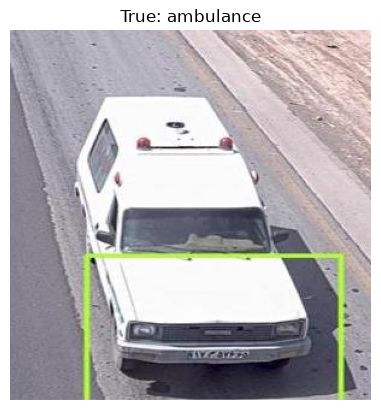

In [27]:

img_path = os.path.join('../data/processed/val/ambulance', '197398569.jpg')
print(f"exists: {os.path.exists(img_path)}")

with Image.open(img_path) as img:
    plt.imshow(img)
    plt.title(f"True: ambulance")
    plt.axis('off')
    plt.show()

In [28]:
test_images = []
for cls in ['ambulance', 'autobus', 'kamyun', 'kamyunet',
            'minibus', 'savari', 'taxi', 'vanet']:
    folder = f'../data/processed/val/{cls}'
    for fname in os.listdir(folder)[:5]:   
        test_images.append({
            'path': os.path.join(folder, fname),
            'true_class': cls,
        })

results = []
for item in test_images:
    r = predict(item['path'])
    results.append({
        'filename': os.path.basename(item['path']),
        'true_class': item['true_class'],
        'predicted_class': r['predicted_class'],
        'confidence': r['confidence'],
        'needs_review': r['needs_review'],
        'correct': item['true_class'] == r['predicted_class'],
    })

df = pd.DataFrame(results)
df.to_csv('../results/prediction_test.csv', index=False)

print(f" {len(df)} predictions saved")
print(f"Accuracy: {df['correct'].mean():.3f}")
print(df.head(10))

 40 predictions saved
Accuracy: 0.850
        filename true_class predicted_class  confidence  needs_review  correct
0  197398569.jpg  ambulance           vanet      0.7449         False    False
1  203829862.jpg  ambulance       ambulance      0.9998         False     True
2  205326290.jpg  ambulance       ambulance      0.7200         False     True
3  206174864.jpg  ambulance           vanet      0.7940         False    False
4  206808986.jpg  ambulance       ambulance      1.0000         False     True
5  193573320.jpg    autobus         autobus      0.9999         False     True
6  193934570.jpg    autobus         autobus      1.0000         False     True
7  195353874.jpg    autobus         autobus      1.0000         False     True
8  196077431.jpg    autobus         autobus      0.9994         False     True
9  196513999.jpg    autobus         autobus      0.9996         False     True
